## RIDGE REGRESSION

In [204]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes

df = load_diabetes(as_frame=True)

In [205]:
x = df.data
y = df.target

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression , Ridge
from sklearn.metrics import mean_squared_error, r2_score

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

lr = Ridge(alpha=0.5)
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R^2 Score:", r2_score(y_test, y_pred))

Mean Squared Error: 2917.176593478921
R^2 Score: 0.4493973121295206


In [206]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=0.5)
ridge.fit(x_train, y_train)
y_pred_ridge = ridge.predict(x_test)
print("Ridge Mean Squared Error:", mean_squared_error(y_test, y_pred_ridge))
print("Ridge R^2 Score:", r2_score(y_test, y_pred_ridge))

Ridge Mean Squared Error: 2917.176593478921
Ridge R^2 Score: 0.4493973121295206


### For Simple Ridge Regression from Scratch

In [207]:
import pandas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

l1_df = pandas.read_csv('/content/Salary_dataset.csv')

l1_df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


<Axes: xlabel='YearsExperience', ylabel='Salary'>

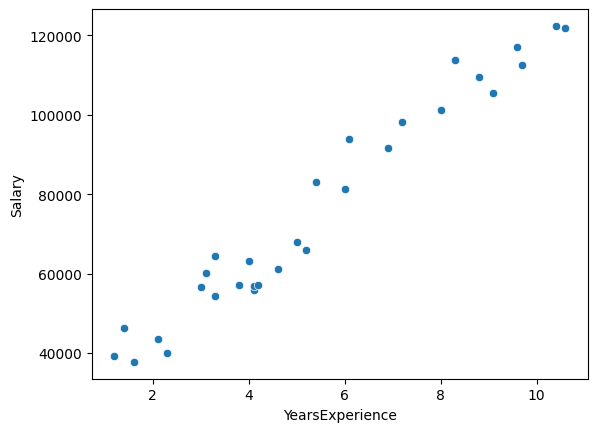

In [208]:
sns.scatterplot(data=l1_df, x='YearsExperience', y='Salary') #Linear Data

In [209]:
x = np.array(l1_df['YearsExperience'])
y = np.array(l1_df['Salary'])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
lam = 0.5

x_mean = np.mean(x_train)
y_mean = np.mean(y_train)

m = np.sum((x_train - x_mean) * (y_train - y_mean)) / (np.sum((x_train - x_mean)**2) + lam)
b = y_mean - m * x_mean

print("Slope (m):", m)
print("Intercept (b):", b)

Slope (m): 9400.223493406602
Intercept (b): 24504.94327861259


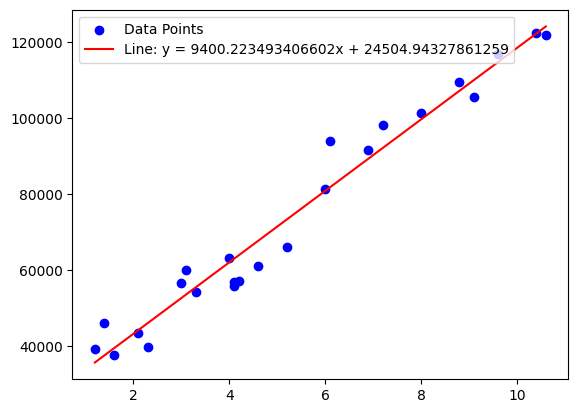

In [210]:
# Generate line x and y coordinates
x_line = np.linspace(min(x_train), max(x_train), 100)
y_line = m * x_line + b

# Plot scatter points and the line
plt.scatter(x_train, y_train, color="blue", label="Data Points")
plt.plot(
    x_line, y_line, color="red", label=f"Line: y = {m}x + {b}"
)  #
plt.legend()
plt.show()


In [211]:
y_pred = m * x_test + b
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R^2 Score:", r2_score(y_test, y_pred))


Mean Squared Error: 49899443.65426669
R^2 Score: 0.9023104151841685


### Simple Ridge Regression using skLearn

In [212]:
rld = Ridge(alpha=0.5)

rld.fit(x_train.reshape(-1, 1), y_train)
rld_pred = rld.predict(x_test.reshape(-1, 1))
print("Mean Squared Error:", mean_squared_error(y_test, rld_pred))
print("R^2 Score:", r2_score(y_test, rld_pred))

Mean Squared Error: 49899443.65426669
R^2 Score: 0.9023104151841685


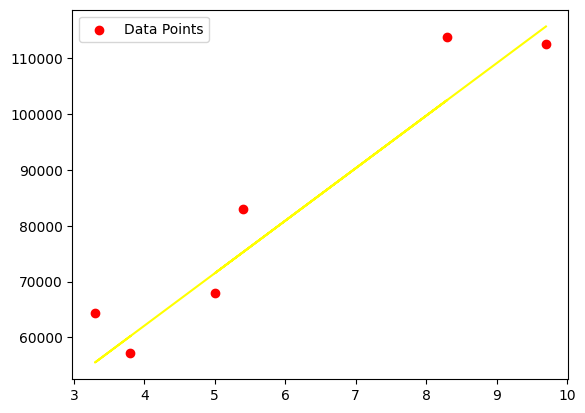

In [215]:
#Plot a line on the scatterplot with the rld_pred
plt.scatter(x_test, y_test, color="red", label="Data Points")
plt.plot(
    x_test, rld_pred , color="yellow"
)
plt.legend()
plt.show()

In [214]:
print(rld.coef_)
print(rld.intercept_)

[9400.22349341]
24504.94327861259


### Ridge Regression for High Dimensional Data